# Predicción de Spending Score
**TP4**

Se evalúa si edad, género e ingreso anual permiten estimar el Spending Score de clientes de un shopping. Se comparan una referencia constante, regresión lineal y dos redes neuronales pequeñas. El objetivo es evaluar la capacidad predictiva y sus límites para apoyar decisiones comerciales.

## Ejecución
Colocar `Mall_Customers.csv` junto a este notebook, instalar las dependencias de `requirements.txt` y ejecutar las celdas en orden. Las salidas guardadas permiten consultar resultados desde GitHub. En Colab, subir el CSV al directorio de trabajo.

**Protocolo:** 120 clientes de entrenamiento, 40 de validación y 40 de prueba; semillas fijas. La selección usa validación. Prueba se evalúa una vez cerrado el conjunto de configuraciones y no se utiliza para ajustes posteriores en este análisis. El score no representa dinero ni probabilidad de compra.


## 1. Datos y controles de calidad

La base contiene 200 clientes. Se comprueban columnas, faltantes, duplicados y unicidad del identificador. Fuente: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).

In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("Mall_Customers.csv")
df_raw = pd.read_csv(DATA_PATH)

print(f"Clientes: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
print(df_raw.head().to_string(index=False))
expected_columns = {"CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"}
assert set(df_raw.columns) == expected_columns, "Revisar columnas del CSV"

print("Tipos de datos:")
print(df_raw.dtypes.to_string())
print("\nValores faltantes:")
print(df_raw.isna().sum().to_string())
print(f"\nFilas completamente duplicadas: {df_raw.duplicated().sum()}")
print(f"CustomerID repetidos: {df_raw['CustomerID'].duplicated().sum()}")
print("Categorías de género:", sorted(df_raw["Gender"].unique()))

assert not df_raw.isna().any().any(), "Hay faltantes por revisar"
assert df_raw["CustomerID"].is_unique, "Hay identificadores repetidos"
assert df_raw["Gender"].isin(["Male", "Female"]).all(), "Categorías inesperadas"
assert df_raw["Spending Score (1-100)"].between(1, 100).all(), "Score fuera de rango"
print("\nControles iniciales: OK")

Clientes: 200 | Columnas: 5
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40
Tipos de datos:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64

Valores faltantes:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0

Filas completamente duplicadas: 0
CustomerID repetidos: 0
Categorías de género: ['Female', 'Male']

Controles iniciales: OK


## 2. Entradas y división de datos

Objetivo: Spending Score. Entradas: género, edad e ingreso. Se excluye CustomerID. Género se codifica Male=0/Female=1, sin significado ordinal. Primero se reserva 20 % para prueba y luego 25 % del resto para validación: reparto final 60/20/20. Se verifican alineación y ausencia de filas compartidas.

In [2]:
FEATURES = ["Gender", "Age", "Annual Income (k$)"]
TARGET = "Spending Score (1-100)"
GENDER_MAPPING = {"Male": 0, "Female": 1}

X = df_raw[FEATURES].copy()
X["Gender"] = X["Gender"].map(GENDER_MAPPING)
y = df_raw[TARGET].copy()

assert not X.isna().any().any()
assert TARGET not in X.columns and "CustomerID" not in X.columns
print("Entradas:", X.columns.tolist())
print("Objetivo:", y.name)
print(X.head().to_string(index=False))
from sklearn.model_selection import train_test_split
import sklearn

SPLIT_SEED = 42
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20
validation_fraction_of_development = VALIDATION_FRACTION / (1 - TEST_FRACTION)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, random_state=SPLIT_SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=validation_fraction_of_development,
    random_state=SPLIT_SEED
)

for label, features, target in [
    ("Entrenamiento", X_train, y_train),
    ("Validación", X_val, y_val),
    ("Prueba", X_test, y_test),
]:
    assert features.index.equals(target.index)
    print(f"{label}: X={features.shape}, y={target.shape}")
print("scikit-learn:", sklearn.__version__)
train_ids = set(X_train.index)
val_ids = set(X_val.index)
test_ids = set(X_test.index)
assert not train_ids & val_ids
assert not train_ids & test_ids
assert not val_ids & test_ids
assert train_ids | val_ids | test_ids == set(X.index)
assert (len(X_train), len(X_val), len(X_test)) == (120, 40, 40)

X_dev_check, X_test_check, _, _ = train_test_split(
    X, y, test_size=TEST_FRACTION, random_state=SPLIT_SEED
)
X_train_check, X_val_check = train_test_split(
    X_dev_check, test_size=validation_fraction_of_development, random_state=SPLIT_SEED
)
assert X_test.index.equals(X_test_check.index)
assert X_train.index.equals(X_train_check.index)
assert X_val.index.equals(X_val_check.index)
print("OK: 120/40/40, sin clientes compartidos, X/y alineados y reparto reproducible.")

Entradas: ['Gender', 'Age', 'Annual Income (k$)']
Objetivo: Spending Score (1-100)
 Gender  Age  Annual Income (k$)
      0   19                  15
      0   21                  15
      1   20                  16
      1   23                  16
      1   31                  17
Entrenamiento: X=(120, 3), y=(120,)
Validación: X=(40, 3), y=(40,)
Prueba: X=(40, 3), y=(40,)
scikit-learn: 1.9.1
OK: 120/40/40, sin clientes compartidos, X/y alineados y reparto reproducible.


## 3. Estandarización

StandardScaler se ajusta solo a edad e ingreso de entrenamiento. Usa desviación poblacional; se aplica sin reajuste a validación y prueba. Género y objetivo conservan su escala. Los controles de media cero y desviación uno corresponden únicamente al entrenamiento.

In [3]:
from sklearn.preprocessing import StandardScaler
import numpy as np

NUMERIC_FEATURES = ["Age", "Annual Income (k$)"]
scaler = StandardScaler()
scaler.fit(X_train[NUMERIC_FEATURES])

def scale_features(features):
    scaled = features.copy()
    scaled[NUMERIC_FEATURES] = scaler.transform(features[NUMERIC_FEATURES])
    return scaled

X_train_scaled = scale_features(X_train)
X_val_scaled = scale_features(X_val)
X_test_scaled = scale_features(X_test)

scaling_parameters = pd.DataFrame({
    "Media entrenamiento": scaler.mean_,
    "Desviación entrenamiento": scaler.scale_,
}, index=NUMERIC_FEATURES)
print(scaling_parameters.round(4).to_string())

example_index = X_train.index[0]
example = pd.DataFrame({
    "Original": X_train.loc[example_index, NUMERIC_FEATURES],
    "Estandarizado": X_train_scaled.loc[example_index, NUMERIC_FEATURES],
})
print("\nEjemplo de entrenamiento (índice original", example_index, "):")
print(example.round(4).to_string())
assert scaler.n_samples_seen_ == len(X_train) == 120
np.testing.assert_allclose(scaler.mean_, X_train[NUMERIC_FEATURES].mean())
np.testing.assert_allclose(scaler.scale_, X_train[NUMERIC_FEATURES].std(ddof=0))
np.testing.assert_allclose(X_train_scaled[NUMERIC_FEATURES].mean(), 0, atol=1e-12)
np.testing.assert_allclose(X_train_scaled[NUMERIC_FEATURES].std(ddof=0), 1, atol=1e-12)

for original, scaled, target in [
    (X_train, X_train_scaled, y_train),
    (X_val, X_val_scaled, y_val),
    (X_test, X_test_scaled, y_test),
]:
    assert original.index.equals(scaled.index)
    assert original.columns.equals(scaled.columns)
    assert scaled["Gender"].equals(original["Gender"])
    assert np.isfinite(scaled.to_numpy()).all()
    pd.testing.assert_series_equal(target, df_raw.loc[target.index, TARGET])
    np.testing.assert_allclose(
        scaler.inverse_transform(scaled[NUMERIC_FEATURES]),
        original[NUMERIC_FEATURES], atol=1e-12
    )

summary = pd.DataFrame({
    "Media escalada": X_train_scaled[NUMERIC_FEATURES].mean(),
    "Desviación escalada": X_train_scaled[NUMERIC_FEATURES].std(ddof=0),
})
print(summary.round(6).to_string())
print("\nOK: escalador ajustado solo a 120 clientes; índices, género y scores conservados.")

                    Media entrenamiento  Desviación entrenamiento
Age                             38.3250                   14.1534
Annual Income (k$)              59.5667                   26.9653

Ejemplo de entrenamiento (índice original 42 ):
                    Original  Estandarizado
Age                       48         0.6836
Annual Income (k$)        39        -0.7627
                    Media escalada  Desviación escalada
Age                           -0.0                  1.0
Annual Income (k$)            -0.0                  1.0

OK: escalador ajustado solo a 120 clientes; índices, género y scores conservados.


## 4. Modelos de referencia

Se ajustan la media del entrenamiento y una regresión lineal. MAE es la métrica principal; RMSE y R² son complementarias. La media minimiza el error cuadrático entre constantes en entrenamiento; la mediana minimiza el absoluto. Los coeficientes lineales representan asociaciones, no causalidad.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train_scaled, y_train)
y_val_pred_baseline = baseline_model.predict(X_val_scaled)

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

baseline_metrics = regression_metrics(y_val, y_val_pred_baseline)
validation_results = pd.DataFrame(
    [baseline_metrics], index=["Media de entrenamiento"]
)
np.testing.assert_allclose(y_val_pred_baseline, y_train.mean())
assert len(y_val_pred_baseline) == len(y_val) == 40

print(f"Score constante aprendido: {y_train.mean():.4f}")
print("\nResultados en validación (40 clientes):")
print(validation_results.round(4).to_string())

baseline_examples = pd.DataFrame({
    "Score real": y_val,
    "Predicción": y_val_pred_baseline,
    "Error absoluto": np.abs(y_val.to_numpy() - y_val_pred_baseline),
})
print("\nPrimeros cinco ejemplos de validación (sin seleccionar por resultado):")
print(baseline_examples.head().round(4).to_string())
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_val_pred_linear = linear_model.predict(X_val_scaled)
linear_metrics = regression_metrics(y_val, y_val_pred_linear)

validation_results = pd.DataFrame(
    [baseline_metrics, linear_metrics],
    index=["Media de entrenamiento", "Regresión lineal"],
)
print("Comparación en validación (40 clientes):")
print(validation_results.round(4).to_string())

mae_reduction = baseline_metrics["MAE"] - linear_metrics["MAE"]
mae_reduction_percent = 100 * mae_reduction / baseline_metrics["MAE"]
print(f"\nReducción de MAE: {mae_reduction:.4f} puntos ({mae_reduction_percent:.2f} %)")
print(f"Intercepto: {linear_model.intercept_:.4f}")
print("Coeficientes:")
print(pd.Series(linear_model.coef_, index=X_train_scaled.columns).round(4).to_string())

linear_examples = pd.DataFrame({
    "Score real": y_val,
    "Media": y_val_pred_baseline,
    "Lineal": y_val_pred_linear,
    "Error absoluto lineal": np.abs(y_val.to_numpy() - y_val_pred_linear),
})
print("\nPrimeros cinco clientes de validación:")
print(linear_examples.head().round(4).to_string())
assert y_val_pred_linear.shape == y_val_pred_baseline.shape == (40,)
assert np.isfinite(y_val_pred_linear).all()
np.testing.assert_allclose(
    y_val_pred_linear,
    X_val_scaled.to_numpy() @ linear_model.coef_ + linear_model.intercept_,
)

Score constante aprendido: 51.7917

Resultados en validación (40 clientes):
                           MAE     RMSE   R2
Media de entrenamiento  22.475  26.8133 -0.0

Primeros cinco ejemplos de validación (sin seleccionar por resultado):
     Score real  Predicción  Error absoluto
34           14     51.7917         37.7917
91           41     51.7917         10.7917
52           54     51.7917          2.2083
194          16     51.7917         35.7917
43           61     51.7917          9.2083
Comparación en validación (40 clientes):
                            MAE     RMSE      R2
Media de entrenamiento  22.4750  26.8133 -0.0000
Regresión lineal        22.0419  25.8339  0.0717

Reducción de MAE: 0.4331 puntos (1.93 %)
Intercepto: 48.4030
Coeficientes:
Gender                5.9800
Age                  -6.9564
Annual Income (k$)    2.6129

Primeros cinco clientes de validación:
     Score real    Media   Lineal  Error absoluto lineal
34           14  51.7917  46.5620                3

## 5. Entrenamiento neuronal con parada temprana

Se compara una capa oculta de 8 neuronas (41 parámetros) con una de 4 (21 parámetros). Ambas usan ReLU, salida lineal, Adam, tasa 0.01, lotes de 16, sin penalización L2 y semilla 42. La salida no impone un límite de 1–100.

`partial_fit` ejecuta una época conservando el estado de Adam. Se monitorea MSE sobre los 40 clientes de validación, con un máximo de 300 épocas, paciencia de 10 y mejora mínima de 0.01. La referencia de paciencia se actualiza con mejoras suficientes; se guardan por separado todos los nuevos mínimos absolutos y se restauran los mejores pesos. Validación no se utiliza para actualizar pesos. El optimizador minimiza la mitad del MSE; las curvas muestran MSE completo.

**Hipótesis del ajuste:** reducir capacidad puede mejorar la generalización. Se modifica solo el tamaño de la capa oculta. La misma semilla con arquitecturas distintas no implica idénticos pesos iniciales ni trayectorias aleatorias; es una comparación exploratoria con una partición y una semilla.


In [6]:
from sklearn.neural_network import MLPRegressor
from copy import deepcopy
from time import perf_counter

NN_SEED = 42
MAX_EPOCHS = 300
PATIENCE = 10
MIN_DELTA = 0.01

def train_network(hidden_units, X_train_scaled, y_train, X_val_scaled, y_val):
    nn_model = MLPRegressor(
        hidden_layer_sizes=(hidden_units,), activation="relu", solver="adam",
        batch_size=16, learning_rate_init=0.01, alpha=0.0,
        random_state=NN_SEED, early_stopping=False, shuffle=True,
    )

    history = []
    best_val_mse = float("inf")
    patience_reference = float("inf")
    wait = 0
    start = perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        nn_model.partial_fit(X_train_scaled, y_train)
        train_mse = mean_squared_error(y_train, nn_model.predict(X_train_scaled))
        val_mse = mean_squared_error(y_val, nn_model.predict(X_val_scaled))
        assert np.isfinite([train_mse, val_mse]).all()
        history.append({"epoch": epoch, "train_mse": train_mse, "val_mse": val_mse})
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch
            best_model = deepcopy(nn_model)
        if val_mse < patience_reference - MIN_DELTA:
            patience_reference = val_mse
            wait = 0
        else:
            wait += 1
        if wait >= PATIENCE:
            break
    training_seconds = perf_counter() - start
    nn_model = best_model
    history_df = pd.DataFrame(history)
    parameter_count = sum(w.size for w in nn_model.coefs_) + sum(b.size for b in nn_model.intercepts_)
    assert parameter_count == 5 * hidden_units + 1
    assert nn_model.out_activation_ == "identity"
    assert len(history_df) <= MAX_EPOCHS
    np.testing.assert_allclose(
        mean_squared_error(y_val, nn_model.predict(X_val_scaled)),
        history_df.val_mse.min(),
    )
    print(f"Tiempo de entrenamiento: {training_seconds:.3f} segundos (este entorno)")
    print(f"Épocas ejecutadas: {epoch}; mejor época: {best_epoch}")
    print("Motivo de parada:", "paciencia agotada" if wait >= PATIENCE else "máximo de épocas")
    print(f"Parámetros: {parameter_count}; mejor MSE validación: {best_val_mse:.4f}")
    return nn_model, history_df, training_seconds, epoch, best_epoch

network_runs = {}
for units in (8, 4):
    print(f"\nRed de {units} neuronas")
    model, history, seconds, stopped_epoch, best_epoch = train_network(
        units, X_train_scaled, y_train, X_val_scaled, y_val
    )
    network_runs[units] = {
        "model": model, "history": history, "seconds": seconds,
        "stopped_epoch": stopped_epoch, "best_epoch": best_epoch,
        "train_metrics": regression_metrics(y_train, model.predict(X_train_scaled)),
        "val_metrics": regression_metrics(y_val, model.predict(X_val_scaled)),
    }



Red de 8 neuronas
Tiempo de entrenamiento: 0.201 segundos (este entorno)
Épocas ejecutadas: 122; mejor época: 112
Motivo de parada: paciencia agotada
Parámetros: 41; mejor MSE validación: 759.8197

Red de 4 neuronas
Tiempo de entrenamiento: 0.302 segundos (este entorno)
Épocas ejecutadas: 234; mejor época: 224
Motivo de parada: paciencia agotada
Parámetros: 21; mejor MSE validación: 685.0384


## 6. Comparación de validación y selección

Se elige la arquitectura neuronal con menor MAE de validación. Se conservan las referencias para la evaluación final. No se reajustan modelos con entrenamiento más validación.

In [7]:
validation_results = pd.DataFrame(
    [baseline_metrics, linear_metrics] + [network_runs[u]["val_metrics"] for u in (8, 4)],
    index=["Media", "Regresión lineal", "Red 8 neuronas", "Red 4 neuronas"],
)
print(validation_results.round(4).to_string())
selected_units = min(network_runs, key=lambda u: network_runs[u]["val_metrics"]["MAE"])
selected_model = network_runs[selected_units]["model"]
print(f"\nArquitectura neuronal seleccionada: {selected_units} neuronas")
print("\nMAE de entrenamiento y validación:")
print(pd.DataFrame({u: {"Entrenamiento": run["train_metrics"]["MAE"],
                       "Validación": run["val_metrics"]["MAE"]}
                    for u, run in network_runs.items()}).round(4).to_string())


                      MAE     RMSE      R2
Media             22.4750  26.8133 -0.0000
Regresión lineal  22.0419  25.8339  0.0717
Red 8 neuronas    23.5445  27.5648 -0.0568
Red 4 neuronas    22.5023  26.1732  0.0472

Arquitectura neuronal seleccionada: 4 neuronas

MAE de entrenamiento y validación:
                     8        4
Entrenamiento  19.1176  19.6566
Validación     23.5445  22.5023


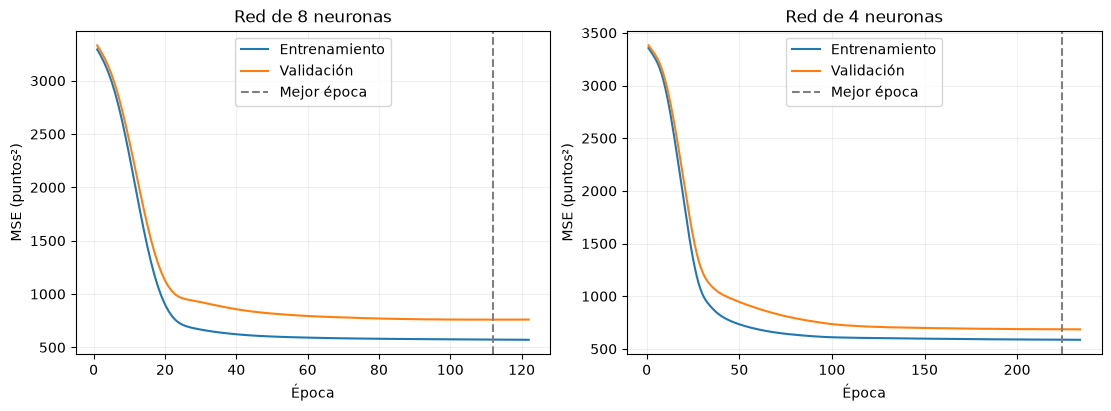

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, (units, run) in zip(axes, network_runs.items()):
    history = run["history"]
    ax.plot(history.epoch, history.train_mse, label="Entrenamiento")
    ax.plot(history.epoch, history.val_mse, label="Validación")
    ax.axvline(run["best_epoch"], color="gray", linestyle="--", label="Mejor época")
    ax.set(title=f"Red de {units} neuronas", xlabel="Época", ylabel="MSE (puntos²)")
    ax.grid(alpha=0.2)
    ax.legend()
plt.show()


La red de cuatro neuronas obtiene menor MAE de validación que la de ocho (22.50 frente a 23.54), pero la regresión lineal alcanza 22.04. La menor brecha entre entrenamiento y validación respalda la hipótesis en este experimento; no prueba ausencia de sobreajuste. La parada temprana limita el entrenamiento sin garantizar precisión predictiva.

## 7. Evaluación final en prueba
Se comparan la media, la regresión lineal y la red elegida sobre los mismos 40 clientes. Las predicciones se evalúan sin recortarlas ni ajustar modelos después de observar estos resultados. Los mayores errores se seleccionan explícitamente para diagnóstico.


In [9]:
final_models = {
    "Media": baseline_model,
    "Regresión lineal": linear_model,
    "Red 4 neuronas": selected_model,
}
test_predictions = {}
test_rows = []
for name, model in final_models.items():
    prediction = model.predict(X_test_scaled)
    assert prediction.shape == (40,)
    assert np.isfinite(prediction).all()
    test_predictions[name] = prediction
    test_rows.append({"Modelo": name, **regression_metrics(y_test, prediction)})
test_results = pd.DataFrame(test_rows).set_index("Modelo")
print("Evaluación final en prueba (40 clientes):")
print(test_results.round(4).to_string())

test_details = df_raw.loc[X_test.index, ["CustomerID", "Gender", "Age", "Annual Income (k$)"]].copy()
test_details["Score real"] = y_test
for name, prediction in test_predictions.items():
    test_details[name] = prediction
# Signo positivo = sobreestimación; negativo = subestimación.
test_details["Error red"] = test_details["Red 4 neuronas"] - test_details["Score real"]
test_details["Error absoluto red"] = test_details["Error red"].abs()
assert test_details.index.equals(y_test.index)
print("\nCinco mayores errores de la red (selección explícita para diagnóstico):")
print(test_details.sort_values("Error absoluto red", ascending=False).head().round(3).to_string(index=False))
print("\nResumen de errores de la red:")
print(f"Error firmado medio: {test_details['Error red'].mean():.4f}")
print(f"Mediana del error absoluto: {test_details['Error absoluto red'].median():.4f}")
print(f"Rango real: {y_test.min():.2f} a {y_test.max():.2f}")
print(f"Rango predicho: {test_details['Red 4 neuronas'].min():.2f} a {test_details['Red 4 neuronas'].max():.2f}")
print("Predicciones fuera de 1–100:", int((~test_details["Red 4 neuronas"].between(1, 100)).sum()))
print("\nMAE red por conjunto:")
print(pd.Series({"Entrenamiento": network_runs[selected_units]["train_metrics"]["MAE"], "Validación": network_runs[selected_units]["val_metrics"]["MAE"], "Prueba": test_results.loc["Red 4 neuronas", "MAE"]}).round(4).to_string())


Evaluación final en prueba (40 clientes):
                      MAE     RMSE      R2
Modelo                                    
Media             18.6688  23.5694 -0.1263
Regresión lineal  17.9908  22.1291  0.0072
Red 4 neuronas    17.5948  21.6167  0.0526

Cinco mayores errores de la red (selección explícita para diagnóstico):
 CustomerID Gender  Age  Annual Income (k$)  Score real  Media  Regresión lineal  Red 4 neuronas  Error red  Error absoluto red
        159   Male   34                  78           1 51.792            52.315          51.639     50.639              50.639
        125 Female   23                  70          29 51.792            62.926          68.537     39.537              39.537
        149 Female   34                  78          22 51.792            58.295          60.132     38.132              38.132
        175 Female   52                  88          13 51.792            50.417          48.651     35.651              35.651
        171   Male   40       

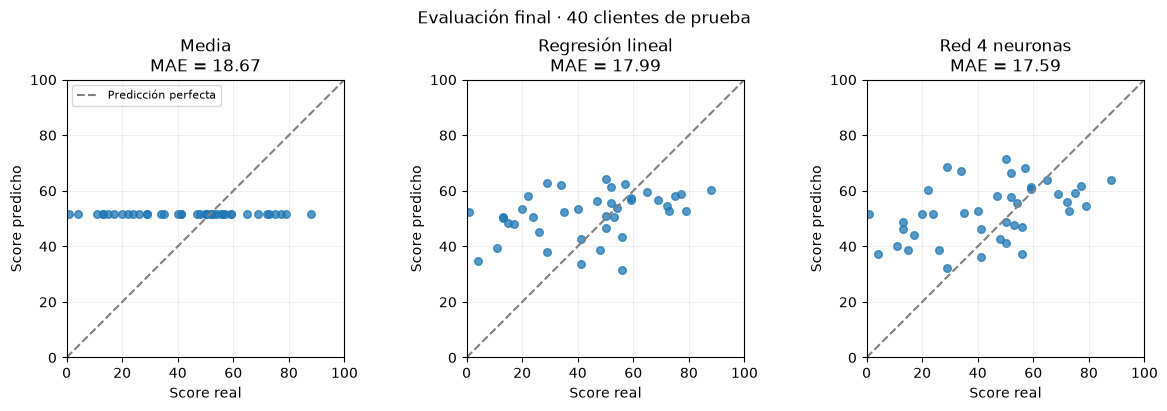

In [10]:
fig_test, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, (name, prediction) in zip(axes, test_predictions.items()):
    ax.scatter(y_test, prediction, alpha=0.75, s=30)
    ax.plot([0, 100], [0, 100], "--", color="gray", label="Predicción perfecta")
    ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="Score real", ylabel="Score predicho",
           title=f"{name}\nMAE = {test_results.loc[name, 'MAE']:.2f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig_test.suptitle("Evaluación final · 40 clientes de prueba")
plt.show()


## 8. Interpretación final y límites

| Modelo | MAE test | RMSE test | R² test |
|---|---:|---:|---:|
| Media de entrenamiento | 18.6688 | 23.5694 | -0.1263 |
| Regresión lineal | 17.9908 | 22.1291 | 0.0072 |
| Red 4 neuronas | 17.5948 | 21.6167 | 0.0526 |

La red elegida por validación entre las dos arquitecturas supera descriptivamente a las referencias en estos 40 clientes. Reduce MAE en 0.3960 puntos frente a la regresión lineal (2.20 %) y 1.0740 frente a la media (5.75 %). La ventaja es pequeña; no se estimó significación estadística ni se demuestra superioridad general. No se usa este resultado para volver a elegir configuraciones. R²=0.0526 corresponde a una reducción de error cuadrático de aproximadamente 5.3 % frente a la media del propio test; no es un porcentaje de exactitud. Esa media de test no se utilizó para entrenar la referencia constante.

El MAE de 17.59 significa un error absoluto promedio de 17.59 puntos de score, no 17.59 % de error. RMSE 21.62 refleja la importancia de errores grandes. Las predicciones de la red van de 32.38 a 71.33, mientras los scores reales de test van de 1 a 88. El gráfico muestra predicciones concentradas en valores intermedios; varios scores bajos se sobreestiman y algunos altos se subestiman. No hubo predicciones fuera del rango 1–100, pero la salida lineal no lo garantiza para futuros datos. El error firmado medio es +8.58: en este conjunto predomina la sobreestimación, aunque también hay subestimaciones.

Ejemplo real del mayor error, seleccionado explícitamente para diagnóstico: CustomerID 159, hombre, 34 años, ingreso anual 78 k$, score real 1, predicción 51.64, error absoluto 50.64 puntos. CustomerID solo identifica la fila; no fue predictor. Este error podría llevar a asignar a un cliente un nivel de score inadecuado si se aplicara un umbral comercial. No evaluamos una política de campaña ni sus costos.

MAE de la red: entrenamiento 19.66, validación 22.50 y test 17.59. Los conjuntos tienen clientes distintos: que test dé menor error no significa que entrenar más ayude ni certifica ausencia de sobreajuste. El experimento está limitado por 200 registros, 40 casos de test, una partición, una semilla. Edad, género e ingreso con estas configuraciones aportan capacidad predictiva limitada; no se demuestra que cualquier otro modelo o información adicional necesariamente fracase.

Conclusión de negocio: no hay evidencia suficiente para respaldar decisiones individuales de campaña basadas únicamente en este score estimado. Harían falta un criterio de error aceptable y evidencia de utilidad comercial. El score no es dinero ni probabilidad de compra, y no demuestra respuesta a promociones, rentabilidad o causalidad.


## 9. Perfiles de consumidores y utilidad comercial

La segmentación del TP1 distingue cinco perfiles según ingreso y score: intermedios en ambas variables; ingreso alto/score alto; ingreso alto/score bajo; ingreso bajo/score bajo; ingreso bajo/score alto. Se retoman como perfiles descriptivos, sin recalcular etiquetas ni definir umbrales nuevos.

Estos grupos utilizan un score conocido; la red busca estimarlo cuando falta. Poder segmentar usando el score no implica poder predecirlo con precisión. Las acciones comerciales basadas en estos perfiles son hipótesis que requieren validación; no se infieren ocupación, motivos de consumo ni respuesta a campañas.

## 10. Conclusión
La red seleccionada alcanza MAE 17.59 en prueba, con una ventaja pequeña frente a las referencias y errores individuales elevados. La evidencia resulta insuficiente para respaldar decisiones individuales de campaña basadas únicamente en el score estimado. El estudio tiene alcance educativo: una base pequeña, una partición y una semilla. No se agregaron configuraciones ni se modificó el entrenamiento a partir de los resultados finales de prueba.


In [ ]:
import platform
import matplotlib

print("Versiones del entorno de ejecución:")
print({"Python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "matplotlib": matplotlib.__version__})


Versiones del entorno de ejecución:
